##**Projet F17 — Prévision des mises en chantier de logements (Housing Starts Forecasting)**

---


**Réalisé par :** Manal El ghafiri et Soha El ghamri, **Groupe 2 FIN2**





---
# Étape 1 — Compréhension du sujet

### Contexte
Une mise en chantier (*housing start*) correspond au début de la construction d'un nouveau logement. La série `HOUST`, publiée par le Census Bureau américain et diffusée par la FRED, est exprimée en **milliers d'unités, en taux annualisé**. Elle est suivie comme indicateur avancé de l'activité du bâtiment et du cycle économique.

### Problématique
**Les mises en chantier de logements suivent-elles une saisonnalité prévisible ?**

### Objectifs
- **Principal :** déterminer s'il existe une saisonnalité exploitable et prévoir les mises en chantier mensuelles.
- **Secondaires :** décrire la tendance et les cycles ; comparer trois modèles de prévision (moyenne saisonnière, Holt-Winters, régression avec variables de mois) par le RMSE et le MAPE sur les 24 derniers mois ; discuter les limites.

### Démarche
Chargement et nettoyage des données, analyse exploratoire, décomposition et test de la saisonnalité, création des variables (mois, retards), séparation chronologique, modélisation, évaluation, conclusion.

In [9]:
# ============================================================
# 0. IMPORTATION DES BIBLIOTHÈQUES
# ============================================================
import warnings
warnings.filterwarnings("ignore")          # masque les avertissements non bloquants

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.graphics.tsaplots import plot_acf

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 4.5)
plt.rcParams["figure.dpi"] = 100

N_TEST = 24        # consigne officielle : 24 derniers mois pour le test
SEED = 42          # reproductibilité (aucun tirage aléatoire n'est utilisé ici)
print("Bibliothèques chargées.")

Bibliothèques chargées.


---
# Étape 2 — Présentation des données

**Objectif :** charger le fichier, identifier les variables et vérifier la période et la fréquence.

In [10]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
# ============================================================
# ÉTAPE 2 — CHARGEMENT ET PREMIER EXAMEN
# ============================================================
import os
import urllib.request

# Chemin vers le fichier HOUST.csv dans votre Google Drive
csv_filename = "/content/drive/MyDrive/PROJET_F17/HOUST.csv"

df_raw = pd.read_csv(csv_filename)                 # lecture du fichier

print("Dimensions (lignes, colonnes) :", df_raw.shape)
print("\nTypes des variables :")
print(df_raw.dtypes)
print("\nCinq premières lignes :")
display(df_raw.head())
print("Cinq dernières lignes :")
display(df_raw.tail())

Dimensions (lignes, colonnes) : (813, 2)

Types des variables :
observation_date    object
HOUST                int64
dtype: object

Cinq premières lignes :


,observation_date,HOUST
0,1959-01-01,1657
1,1959-02-01,1667
2,1959-03-01,1620
3,1959-04-01,1590
4,1959-05-01,1498


Cinq dernières lignes :


,observation_date,HOUST
808,2026-05-01,1182
809,2026-06-01,1439
810,2026-07-01,1369
811,2026-08-01,1288
812,2026-09-01,1221


In [12]:
# Période couverte et fréquence
dates = pd.to_datetime(df_raw["observation_date"])
print("Première date :", dates.min().date())
print("Dernière date :", dates.max().date())

# Si la série est mensuelle et complète, il doit y avoir exactement ce nombre de mois :
nb_mois_attendus = len(pd.date_range(dates.min(), dates.max(), freq="MS"))
print("Nombre de mois entre la première et la dernière date :", nb_mois_attendus)
print("Nombre d'observations dans le fichier              :", len(df_raw))

# Tous les jours sont-ils bien des « premiers du mois » ?
print("Toutes les dates sont des débuts de mois :", bool((dates.dt.day == 1).all()))

Première date : 1959-01-01
Dernière date : 2026-09-01
Nombre de mois entre la première et la dernière date : 813
Nombre d'observations dans le fichier              : 813
Toutes les dates sont des débuts de mois : True


### Interprétation
Le fichier contient **813 lignes et 2 colonnes** : `observation_date` (date, lue comme texte au chargement) et `HOUST` (entier, milliers d'unités en taux annualisé). La période couvre **janvier 1959 – septembre 2026**, soit exactement 813 mois : la fréquence est **mensuelle** et aucun mois ne manque.

---
# Étape 3 — Nettoyage et préparation des données

**Objectif :** vérifier la qualité des données (valeurs manquantes, doublons, format de date), trier chronologiquement et définir la date comme index. Aucune donnée n'est supprimée sans justification.

In [13]:
# ============================================================
# ÉTAPE 3 — NETTOYAGE ET PRÉPARATION
# ============================================================
df = df_raw.copy()

# 3.1 Valeurs manquantes
print("Valeurs manquantes par colonne :")
print(df.isna().sum())

# 3.2 Doublons (lignes entières et dates répétées)
print("\nLignes dupliquées :", df.duplicated().sum())
print("Dates dupliquées  :", df["observation_date"].duplicated().sum())

# 3.3 Conversion du format de date (texte -> datetime)
df["observation_date"] = pd.to_datetime(df["observation_date"], format="%Y-%m-%d")

# 3.4 Tri chronologique + 3.5 date comme index
df = df.sort_values("observation_date").set_index("observation_date")
df.index.name = "date"

# 3.6 Fréquence mensuelle explicite (MS = Month Start). Vérifie aussi qu'aucun mois ne manque.
df = df.asfreq("MS")
print("\nAprès asfreq('MS') -> valeurs manquantes :", df["HOUST"].isna().sum())
print("Index trié chronologiquement :", df.index.is_monotonic_increasing)

# La série étudiée (pandas Series) : mises en chantier en milliers d'unités
y = df["HOUST"].astype(float)
y.name = "HOUST"
print("\nSérie prête :", y.shape, "| fréquence :", y.index.freqstr)
display(y.head())

Valeurs manquantes par colonne :
observation_date    0
HOUST               0
dtype: int64

Lignes dupliquées : 0
Dates dupliquées  : 0

Après asfreq('MS') -> valeurs manquantes : 0
Index trié chronologiquement : True

Série prête : (813,) | fréquence : MS


,HOUST
date,
1959-01-01,1657.0
1959-02-01,1667.0
1959-03-01,1620.0
1959-04-01,1590.0
1959-05-01,1498.0


### Interprétation
Le fichier ne contient **aucune valeur manquante, aucune ligne dupliquée ni aucune date dupliquée**. Il est déjà trié ; après conversion au format date et imposition d'une fréquence mensuelle (`asfreq("MS")`), la série reste complète. **Aucune donnée n'a été supprimée ni modifiée.**

**Risque de révision.** Les mises en chantier sont révisées après leur publication. Le fichier correspond à une version donnée de la série : les valeurs les plus récentes peuvent encore changer, ce qui affecte les erreurs mesurées sur la période de test.

---
# Étape 4 — Analyse exploratoire des données

**Objectif :** résumer la série par des statistiques descriptives et étudier son évolution.

In [14]:
# ============================================================
# ÉTAPE 4 — ANALYSE EXPLORATOIRE
# ============================================================
desc = y.describe().round(1)
desc["médiane"] = y.median()
desc["coef. de variation (%)"] = round(100 * y.std() / y.mean(), 1)
display(desc.to_frame("HOUST"))

print("Minimum atteint en :", y.idxmin().strftime("%Y-%m"), "->", int(y.min()))
print("Maximum atteint en :", y.idxmax().strftime("%Y-%m"), "->", int(y.max()))

# Moyenne par décennie : montre l'évolution du niveau
par_decennie = y.groupby((y.index.year // 10) * 10).agg(["mean", "std", "min", "max"]).round(0)
par_decennie.index.name = "décennie"
display(par_decennie)

,HOUST
count,813.0
mean,1430.2
std,375.2
min,478.0
25%,1214.0
50%,1448.0
75%,1641.0
max,2494.0
médiane,1448.0
coef. de variation (%),26.2


Minimum atteint en : 2009-04 -> 478
Maximum atteint en : 1972-01 -> 2494


,mean,std,min,max
décennie,,,,
1950,1535.0,99.0,1355.0,1667.0
1960,1407.0,183.0,843.0,1820.0
1970,1758.0,405.0,904.0,2494.0
1980,1498.0,301.0,837.0,2260.0
1990,1372.0,209.0,798.0,1792.0
2000,1537.0,473.0,478.0,2273.0
2010,994.0,258.0,517.0,1548.0
2020,1438.0,154.0,936.0,1807.0


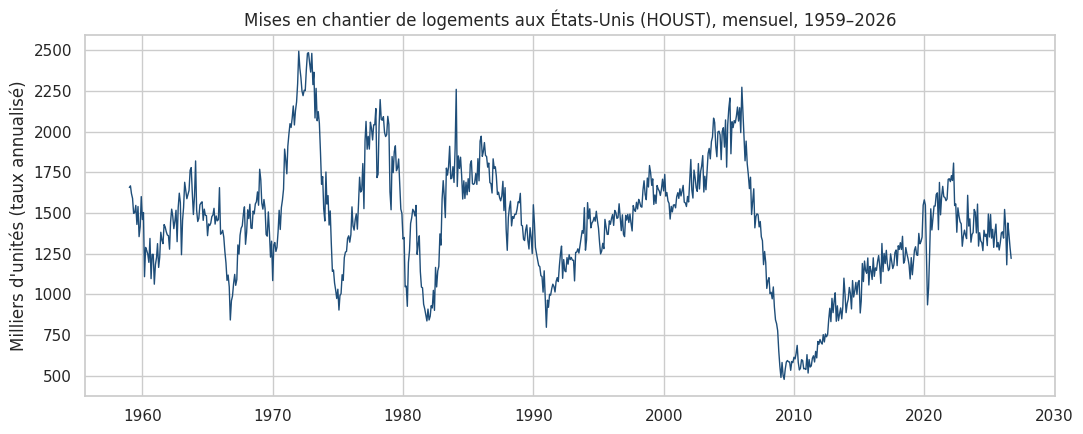

In [15]:
# Graphique 1 : évolution de la série complète
fig, ax = plt.subplots()
ax.plot(y.index, y.values, lw=1, color="#1f4e79")
ax.set_title("Mises en chantier de logements aux États-Unis (HOUST), mensuel, 1959–2026")
ax.set_ylabel("Milliers d'unités (taux annualisé)")
ax.set_xlabel("")
plt.tight_layout(); plt.show()

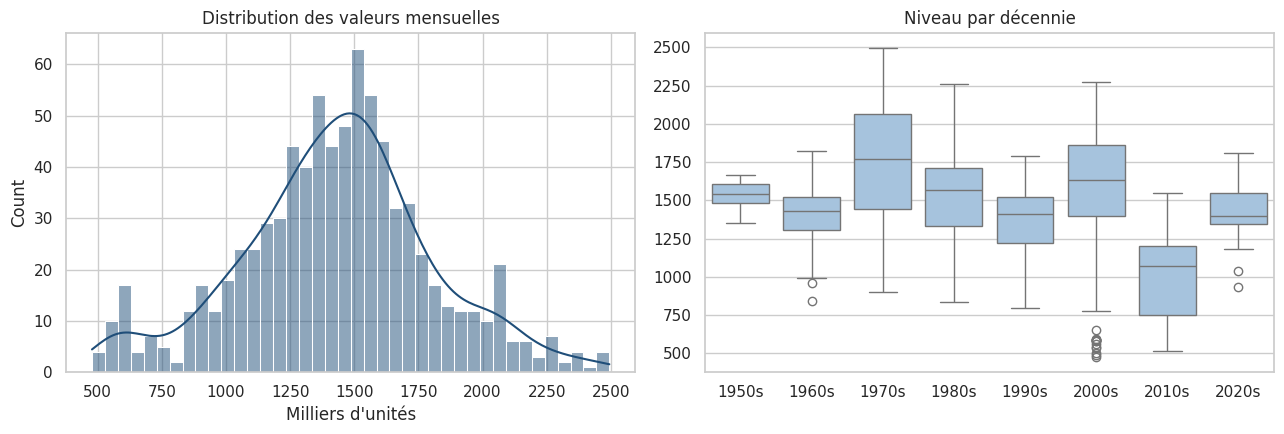

In [16]:
# Graphique 2 : distribution + boxplot par décennie
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(y, bins=40, kde=True, ax=axes[0], color="#1f4e79")
axes[0].set_title("Distribution des valeurs mensuelles")
axes[0].set_xlabel("Milliers d'unités")

dec = pd.DataFrame({"HOUST": y, "décennie": ((y.index.year // 10) * 10).astype(str) + "s"})
sns.boxplot(data=dec, x="décennie", y="HOUST", ax=axes[1], color="#9dc3e6")
axes[1].set_title("Niveau par décennie")
axes[1].set_xlabel(""); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

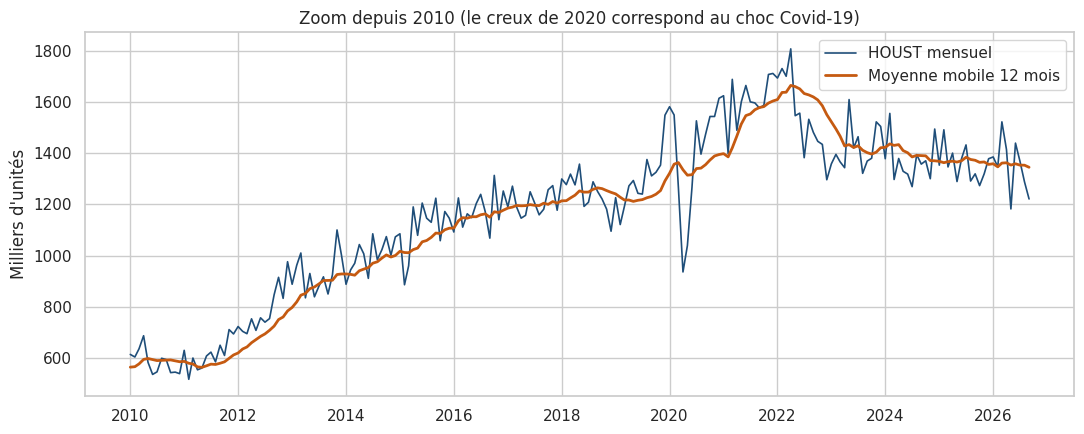

Variation mensuelle moyenne : 0.30 % | écart-type : 8.25 %
Plus forte baisse mensuelle : 1984-03 -26.4 %
Plus forte hausse mensuelle : 1982-07 29.3 %


In [17]:
# Graphique 3 : zoom sur les 15 dernières années + moyenne mobile 12 mois
fig, ax = plt.subplots()
rec = y["2010":]
ax.plot(rec.index, rec.values, lw=1.2, label="HOUST mensuel", color="#1f4e79")
ax.plot(rec.index, y.rolling(12).mean()["2010":], lw=2, label="Moyenne mobile 12 mois", color="#c55a11")
ax.set_title("Zoom depuis 2010 (le creux de 2020 correspond au choc Covid-19)")
ax.legend(); ax.set_ylabel("Milliers d'unités")
plt.tight_layout(); plt.show()

# Variations mensuelles en % : la série est-elle « nerveuse » d'un mois à l'autre ?
var = y.pct_change().dropna() * 100
print("Variation mensuelle moyenne : %.2f %% | écart-type : %.2f %%" % (var.mean(), var.std()))
print("Plus forte baisse mensuelle :", var.idxmin().strftime("%Y-%m"), "%.1f %%" % var.min())
print("Plus forte hausse mensuelle :", var.idxmax().strftime("%Y-%m"), "%.1f %%" % var.max())

### Interprétation
**Statistiques descriptives.** Moyenne **1 430**, médiane **1 448**, écart-type **375**, minimum **478** (avril 2009), maximum **2 494** (janvier 1972). Moyenne et médiane sont proches : la distribution est à peu près symétrique. Le coefficient de variation (26 %) traduit de fortes variations de niveau.

**Évolution de la série.** La série ne présente pas de tendance linéaire simple : elle alterne de **grands cycles** (pics au début et à la fin des années 1970, en 1984-1986, en 2005) et de creux marqués (1975, 1982, 1991, 2009). L'effondrement de 2006-2009 est le plus fort ; la moyenne des années 2010 (994) est nettement inférieure à celle des années 2000 (1 537).

**Distribution et décennies.** Les boxplots par décennie montrent des **changements de niveau** importants : la série n'est pas stationnaire en moyenne.

**Variations mensuelles.** La variation moyenne d'un mois à l'autre est de +0,30 % avec un écart-type de **8,25 %** (extrêmes : −26,4 % en mars 1984, +29,3 % en juillet 1982). Le creux de 2020 correspond au choc Covid-19. La série est donc fortement bruitée à court terme.

---
# Étape 5 — Tendance et saisonnalité

**Objectif :** étudier la tendance, décomposer la série (tendance, saisonnalité, résidu) et vérifier statistiquement l'existence d'une saisonnalité.

**Série déjà corrigée ou non des variations saisonnières ?** La série `HOUST` publiée par la FRED est une série **corrigée des variations saisonnières** (*Seasonally Adjusted Annual Rate*, SAAR). La FRED publie séparément la série non corrigée `HOUSTNSA`, qui n'est pas dans le fichier fourni. Cette information doit être confirmée par les données : une décomposition fournit toujours une composante « saisonnière » (moyenne par mois), même en l'absence de saisonnalité ; il faut donc **mesurer son amplitude et la tester**.

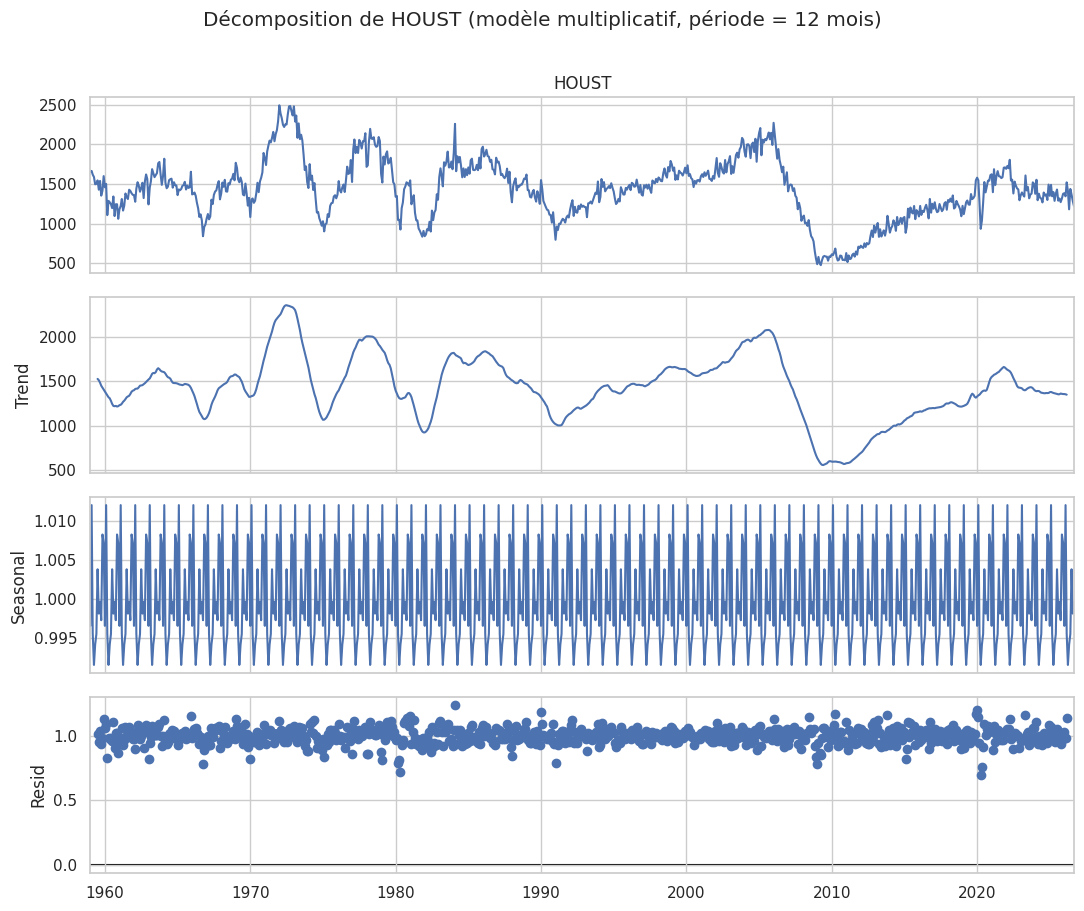

In [18]:
# ============================================================
# ÉTAPE 5 — TENDANCE ET SAISONNALITÉ
# ============================================================
# 5.1 Décomposition multiplicative : série = tendance x saisonnalité x résidu
#     (multiplicative car l'amplitude des fluctuations grandit avec le niveau)
dec = seasonal_decompose(y, model="multiplicative", period=12)

fig = dec.plot()
fig.set_size_inches(11, 9)
fig.suptitle("Décomposition de HOUST (modèle multiplicatif, période = 12 mois)", y=1.01)
plt.tight_layout()
fig.savefig("decomposition_HOUST.png", dpi=150, bbox_inches="tight")   # livrable : graphique de décomposition
plt.show()

,Jan,Fév,Mar,Avr,Mai,Juin,Juil,Août,Sep,Oct,Nov,Déc
coefficient saisonnier,0.9966,1.0121,0.9956,0.9916,0.9942,0.9955,1.0038,0.9982,0.9997,0.9973,1.0083,1.0072


Amplitude saisonnière (max - min)      : 2.05 % du niveau
Écart-type des résidus                 : 6.30 % du niveau
Rapport amplitude saisonnière / bruit  : 0.33


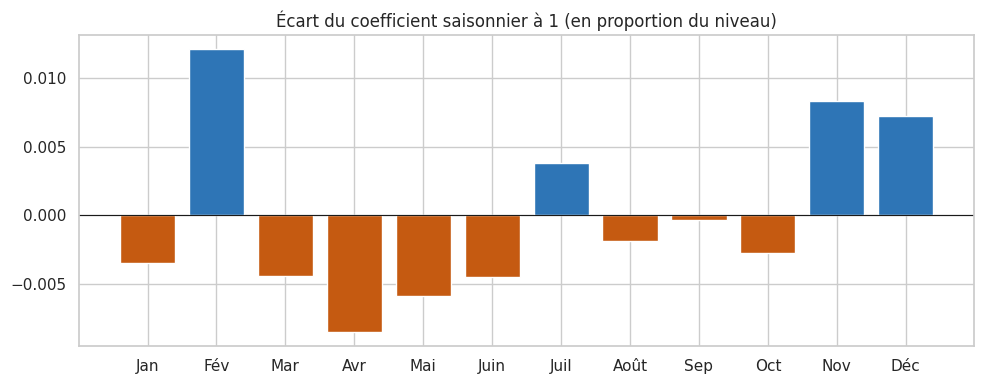

In [19]:
# 5.2 Coefficients saisonniers estimés (1.00 = aucun effet saisonnier)
coef = dec.seasonal.groupby(dec.seasonal.index.month).mean()
coef.index = ["Jan","Fév","Mar","Avr","Mai","Juin","Juil","Août","Sep","Oct","Nov","Déc"]
display(coef.round(4).to_frame("coefficient saisonnier").T)

amp_saison = (dec.seasonal.max() - dec.seasonal.min()) * 100
ecart_resid = dec.resid.std() * 100
print("Amplitude saisonnière (max - min)      : %.2f %% du niveau" % amp_saison)
print("Écart-type des résidus                 : %.2f %% du niveau" % ecart_resid)
print("Rapport amplitude saisonnière / bruit  : %.2f" % (amp_saison / ecart_resid))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(coef.index, coef.values - 1, color=np.where(coef.values >= 1, "#2e75b6", "#c55a11"))
ax.axhline(0, color="k", lw=0.8)
ax.set_title("Écart du coefficient saisonnier à 1 (en proportion du niveau)")
plt.tight_layout(); plt.show()

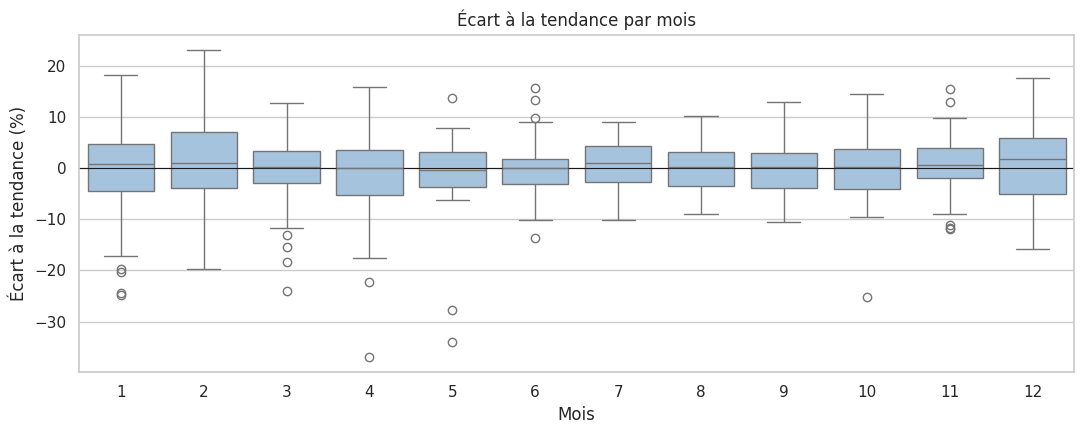

ANOVA          : F = 0.688, p-value = 0.751
Kruskal-Wallis : H = 6.376, p-value = 0.847


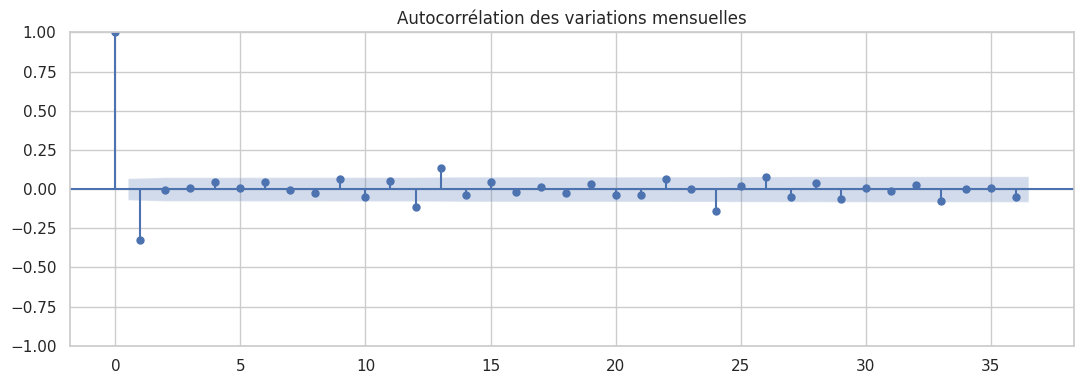

In [20]:
# 5.3 Test statistique de la saisonnalité
# On retire la tendance (écart relatif au niveau lissé sur 13 mois centrés), puis on teste l'effet du mois.
log_y = np.log(y)
ecart = (log_y - log_y.rolling(13, center=True).mean()).dropna()
mois = ecart.index.month

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(x=mois, y=ecart.values * 100, ax=ax, color="#9dc3e6")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("Mois"); ax.set_ylabel("Écart à la tendance (%)")
ax.set_title("Écart à la tendance par mois")
plt.tight_layout(); plt.show()

# H0 : les 12 mois ont la même moyenne (absence de saisonnalité)
groupes = [ecart[mois == m].values for m in range(1, 13)]
anova = stats.f_oneway(*groupes)
kw = stats.kruskal(*groupes)
print("ANOVA          : F = %.3f, p-value = %.3f" % (anova.statistic, anova.pvalue))
print("Kruskal-Wallis : H = %.3f, p-value = %.3f" % (kw.statistic, kw.pvalue))

# Autocorrélation de la série différenciée : un pic à 12, 24, 36 indiquerait une saisonnalité annuelle
fig, ax = plt.subplots(figsize=(11, 4))
plot_acf(y.diff().dropna(), lags=36, ax=ax)
ax.set_title("Autocorrélation des variations mensuelles")
plt.tight_layout(); plt.show()

### Interprétation
**Décomposition (modèle multiplicatif, période 12).** La tendance reprend les grands cycles de l'étape 4. La composante saisonnière est identique chaque année par construction ; son axe va seulement de 0,992 à 1,012. Le coefficient le plus élevé est celui de février (1,012), le plus bas celui d'avril (0,992) : l'amplitude totale est de **2,05 %** du niveau, contre un écart-type des résidus de **6,30 %**. L'effet saisonnier est trois fois plus faible que le bruit (rapport 0,33).

**Tests de saisonnalité** (H0 : les 12 mois ont la même moyenne, après retrait de la tendance) :

| Test | Statistique | p-value |
|---|---|---|
| ANOVA | F = 0,688 | 0,751 |
| Kruskal-Wallis | H = 6,376 | 0,847 |

Les p-values sont très supérieures à 0,05 : **l'hypothèse d'absence de saisonnalité n'est pas rejetée**. Les boîtes du boxplot par mois se chevauchent toutes et l'autocorrélation ne présente aucun pic net aux retards 12, 24 et 36.

**Conclusion de l'étape.** La série `HOUST` ne présente **pas de saisonnalité mensuelle détectable**. Ce résultat est cohérent avec le fait que la série est déjà corrigée des variations saisonnières : la faible composante saisonnière de la décomposition est du bruit et non un signal. Il ne renseigne pas sur la saisonnalité de la construction réelle, qui nécessiterait la série non corrigée `HOUSTNSA`.

---
# Étape 6 — Feature engineering

**Objectif :** créer les variables explicatives de la régression en utilisant uniquement le passé.

| Variable | Contenu | Utilité |
|---|---|---|
| `mois` (11 indicatrices) | numéro du mois (1 à 12), janvier en référence | capter un effet saisonnier moyen |
| `lag_1` | valeur du mois précédent | inertie à court terme |
| `lag_2` | valeur d'il y a 2 mois | mémoire plus longue |
| `lag_12` | valeur du même mois l'année précédente | lien annuel |

La fonction `shift(k)` décale la série de *k* mois : à la date *t*, `lag_k` contient *y(t−k)*, donc uniquement des informations passées. On crée 11 indicatrices et non 12 pour éviter la colinéarité avec la constante.

In [21]:
# ============================================================
# ÉTAPE 6 — FEATURE ENGINEERING
# ============================================================
data = pd.DataFrame({"y": y})

# 6.1 Variable mois (1 à 12) et ses 11 indicatrices (le mois 1 sert de référence)
data["mois"] = data.index.month
dummies = pd.get_dummies(data["mois"], prefix="mois", drop_first=True).astype(int)

# 6.2 Variables retardées : shift(k) décale la série de k mois vers le BAS.
#     À la date t, lag_k contient donc y(t-k), c'est-à-dire uniquement du PASSÉ.
data["lag_1"] = data["y"].shift(1)     # inertie : le mois précédent
data["lag_2"] = data["y"].shift(2)     # mémoire un peu plus longue
data["lag_12"] = data["y"].shift(12)   # même mois l'an dernier (capte une saisonnalité annuelle)

feat = pd.concat([data, dummies], axis=1)
print("Lignes avant suppression des NaN :", len(feat))
feat = feat.dropna()                   # perte inévitable : les 12 premiers mois n'ont pas de lag_12
print("Lignes après suppression des NaN :", len(feat), "(12 premières observations perdues, c'est normal)")
display(feat[["y", "mois", "lag_1", "lag_2", "lag_12"]].head(4))

# 6.3 Contrôle anti-fuite : lag_1(t) doit être égal à y(t-1) pour toute date t
t = feat.index[100]
print("\nContrôle : y au mois précédent", t.strftime("%Y-%m"), "=", y.shift(1)[t], "| lag_1 =", feat.loc[t, "lag_1"])
assert (feat["lag_1"] == y.shift(1).loc[feat.index]).all()
assert (feat["lag_12"] == y.shift(12).loc[feat.index]).all()
print("Contrôles anti-fuite réussis.")

Lignes avant suppression des NaN : 813
Lignes après suppression des NaN : 801 (12 premières observations perdues, c'est normal)


,y,mois,lag_1,lag_2,lag_12
date,,,,,
1960-01-01,1460.0,1,1601.0,1416.0,1657.0
1960-02-01,1503.0,2,1460.0,1601.0,1667.0
1960-03-01,1109.0,3,1503.0,1460.0,1620.0
1960-04-01,1289.0,4,1109.0,1503.0,1590.0



Contrôle : y au mois précédent 1968-05 = 1554.0 | lag_1 = 1554.0
Contrôles anti-fuite réussis.


### Interprétation
12 observations sont perdues (801 restantes) car les 12 premiers mois n'ont pas de `lag_12`. Les contrôles confirment que `lag_1` et `lag_12` correspondent exactement aux valeurs des mois *t−1* et *t−12* : **aucune information future n'entre dans les variables explicatives**, il n'y a donc pas de fuite de données.

---
# Étape 7 — Division des données

**Objectif :** séparer les données en respectant l'ordre chronologique, avec les 24 dernières observations mensuelles en test.

**Justification.** Dans une série temporelle, un découpage aléatoire ferait entraîner le modèle sur des observations postérieures à celles qu'il doit prévoir. Le test est donc placé **strictement après** l'entraînement, comme en situation réelle de prévision.

Entraînement : 1959-01 -> 2024-09 | 789 mois
Test         : 2024-10 -> 2026-09 | 24 mois

Lignes de régression utilisables pour l'entraînement : 777


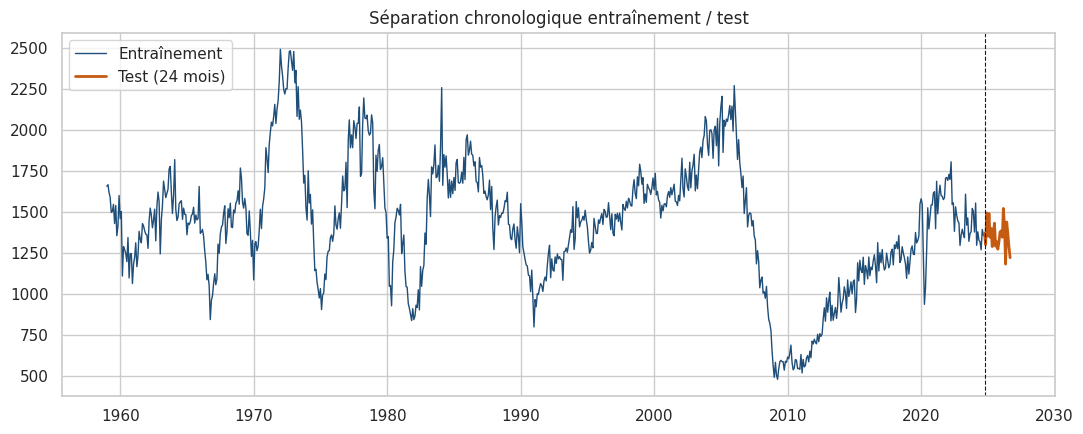

In [22]:
# ============================================================
# ÉTAPE 7 — DIVISION CHRONOLOGIQUE (24 DERNIERS MOIS = TEST)
# ============================================================
train = y.iloc[:-N_TEST]          # tout sauf les 24 derniers mois
test = y.iloc[-N_TEST:]           # les 24 derniers mois

print("Entraînement :", train.index[0].strftime("%Y-%m"), "->", train.index[-1].strftime("%Y-%m"), "|", len(train), "mois")
print("Test         :", test.index[0].strftime("%Y-%m"), "->", test.index[-1].strftime("%Y-%m"), "|", len(test), "mois")
assert train.index.max() < test.index.min()      # le test est strictement postérieur

# Version « features » pour la régression : même coupure de date
feat_train = feat.loc[:train.index[-1]]
print("\nLignes de régression utilisables pour l'entraînement :", len(feat_train))

fig, ax = plt.subplots()
ax.plot(train.index, train.values, lw=1, label="Entraînement", color="#1f4e79")
ax.plot(test.index, test.values, lw=2, label="Test (24 mois)", color="#c55a11")
ax.axvline(test.index[0], color="k", ls="--", lw=0.8)
ax.set_title("Séparation chronologique entraînement / test"); ax.legend()
plt.tight_layout(); plt.show()

### Interprétation
- **Entraînement :** 789 mois (janvier 1959 – septembre 2024).
- **Test :** 24 mois (octobre 2024 – septembre 2026).
- Pour la régression, 777 lignes sont utilisables à l'entraînement (après perte des 12 premiers mois).

---
# Étape 8 — Construction des modèles de prévision

**Objectif :** construire les trois modèles et les évaluer dans les mêmes conditions : prévision de 24 mois à partir de septembre 2024, sans utiliser les valeurs réelles de la période de test.

### Paramètres de Holt-Winters
- **α** (niveau) : plus il est élevé, plus le niveau suit les observations récentes.
- **β** (tendance) et **φ** (amortissement) : φ < 1 amortit la tendance pour éviter de l'extrapoler indéfiniment.
- **γ** (saison) : vitesse de mise à jour du profil saisonnier ; γ = 0 signifie qu'il n'est jamais révisé.
- La saison est **additive** (écart constant) ou **multiplicative** (écart proportionnel au niveau).

La configuration est choisie sur l'**entraînement** par le critère AIC, et non sur le test, afin de conserver l'indépendance de l'évaluation.

In [23]:
# ============================================================
# ÉTAPE 8 — MODÈLES
# Règle commune à tous les modèles : on se place fin 2024-09 (dernière date d'entraînement)
# et on prévoit les 24 mois suivants SANS jamais voir les vraies valeurs du test.
# ============================================================
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def mape(y_true, y_pred):                       # en pourcentage
    return float(100 * mean_absolute_percentage_error(y_true, y_pred))

forecasts = {}                                  # dictionnaire qui stockera les prévisions de chaque modèle

In [24]:
# 8.1 BASELINE — moyenne saisonnière mensuelle (calculée sur l'entraînement uniquement)
moy_mois = train.groupby(train.index.month).mean()
display(moy_mois.round(1).to_frame("moyenne d'entraînement").T)

forecasts["Baseline (moyenne par mois)"] = pd.Series(
    [moy_mois[m] for m in test.index.month], index=test.index)

date,1,2,3,4,5,6,7,8,9,10,11,12
moyenne d'entraînement,1431.9,1452.3,1426.4,1419.9,1425.3,1423.7,1433.7,1429.2,1429.7,1429.7,1444.5,1443.2


In [25]:
# 8.2 HOLT-WINTERS : plusieurs configurations comparées sur l'ENTRAÎNEMENT (critère AIC, plus bas = meilleur)
configs = [
    ("Sans tendance, saison additive",          dict(trend=None,  seasonal="add", seasonal_periods=12)),
    ("Sans tendance, saison multiplicative",    dict(trend=None,  seasonal="mul", seasonal_periods=12)),
    ("Tendance amortie, saison additive",       dict(trend="add", seasonal="add", seasonal_periods=12, damped_trend=True)),
    ("Tendance amortie, saison multiplicative", dict(trend="add", seasonal="mul", seasonal_periods=12, damped_trend=True)),
]
fits, lignes = {}, []
for nom, kw in configs:
    fit = ExponentialSmoothing(train, initialization_method="estimated", **kw).fit()
    fits[nom] = fit
    lignes.append([nom, fit.aic])
grille = pd.DataFrame(lignes, columns=["configuration", "AIC (entraînement)"]).round(2)
display(grille.sort_values("AIC (entraînement)"))

nom_hw = grille.loc[grille["AIC (entraînement)"].idxmin(), "configuration"]
print("Configuration retenue :", nom_hw)
forecasts["Holt-Winters"] = fits[nom_hw].forecast(N_TEST)

p = fits[nom_hw].params
display(pd.Series({"alpha (niveau)": p["smoothing_level"], "beta (tendance)": p["smoothing_trend"],
                   "gamma (saison)": p["smoothing_seasonal"], "phi (amortissement)": p["damping_trend"]}).round(4).to_frame("valeur"))

,configuration,AIC (entraînement)
3,"Tendance amortie, saison multiplicative",7410.25
2,"Tendance amortie, saison additive",7411.87
1,"Sans tendance, saison multiplicative",7412.72
0,"Sans tendance, saison additive",7414.09


Configuration retenue : Tendance amortie, saison multiplicative


,valeur
alpha (niveau),0.5769
beta (tendance),0.0888
gamma (saison),0.0000
phi (amortissement),0.8552


In [26]:
# 8.3 RÉGRESSION avec variables de mois + lag_1, lag_2, lag_12
cols = ["lag_1", "lag_2", "lag_12"] + list(dummies.columns)

reg = LinearRegression()
reg.fit(feat_train[cols], feat_train["y"])
print("R² sur l'entraînement : %.3f" % reg.score(feat_train[cols], feat_train["y"]))
coefs = pd.Series(reg.coef_, index=cols).round(4)
display(coefs.to_frame("coefficient").T)

# PRÉVISION RÉCURSIVE : pour 2024-10, lag_1, lag_2 et lag_12 viennent de l'entraînement ;
# pour 2024-11, lag_1 est la PRÉVISION de 2024-10, etc. Aucune vraie valeur du test n'est utilisée.
historique = train.copy()                           # série connue au départ
preds = []
for date in test.index:
    x = {"lag_1": historique.iloc[-1], "lag_2": historique.iloc[-2], "lag_12": historique.iloc[-12]}
    for c in dummies.columns:                       # indicatrices du mois à prévoir
        x[c] = 1 if c == f"mois_{date.month}" else 0
    p = float(reg.predict(pd.DataFrame([x])[cols])[0])
    preds.append(p)
    historique.loc[date] = p                        # la prévision devient un « passé » pour le pas suivant

forecasts["Régression"] = pd.Series(preds, index=test.index)
assert historique.iloc[:len(train)].equals(train)  # l'entraînement n'a pas été modifié
print("\nPrévision récursive terminée (", len(preds), "mois ).")

R² sur l'entraînement : 0.921


,lag_1,lag_2,lag_12,mois_2,mois_3,mois_4,mois_5,mois_6,mois_7,mois_8,mois_9,mois_10,mois_11,mois_12
coefficient,0.6741,0.3202,-0.0339,31.5324,-3.9815,0.3083,19.7741,15.3423,24.165,15.235,13.0248,16.5214,30.1463,15.8411



Prévision récursive terminée ( 24 mois ).


### Interprétation
**Baseline.** Les moyennes mensuelles de l'entraînement sont toutes comprises entre 1 420 et 1 452 : le profil est presque plat, ce qui confirme l'absence de saisonnalité marquée.

**Holt-Winters.** Les AIC des quatre configurations sont proches (7 410 à 7 414). La configuration **tendance amortie + saison multiplicative** est retenue (AIC le plus faible). Ses paramètres sont α = 0,577, β = 0,089, φ = 0,855 et **γ = 0,000** : le profil saisonnier n'est jamais mis à jour, ce qui indique que la composante saisonnière apporte peu d'information.

**Régression.** Le R² d'entraînement est de 0,921, mais il provient essentiellement de `lag_1` (0,674) et `lag_2` (0,320) ; `lag_12` est quasi nul (−0,034) et les coefficients de mois sont faibles (de −4 à +32 par rapport à janvier, pour un niveau d'environ 1 400) sans profil saisonnier cohérent. La régression prévoit donc principalement par **inertie**, non par saisonnalité.

**Prévision récursive.** Après le premier mois, `lag_1` et `lag_2` sont remplacés par les prévisions précédentes, les vraies valeurs n'étant pas connues ; les erreurs peuvent donc s'accumuler.

---
# Étape 9 — Évaluation des modèles

**Objectif :** comparer les modèles sur les 24 mois de test avec le **RMSE** (racine de l'erreur quadratique moyenne, en milliers d'unités, pénalise les grosses erreurs) et le **MAPE** (erreur absolue moyenne en pourcentage de la valeur réelle). Plus ces valeurs sont faibles, meilleur est le modèle.

In [27]:
# ============================================================
# ÉTAPE 9 — ÉVALUATION (mêmes 24 mois, mêmes conditions pour tous les modèles)
# ============================================================
res = pd.DataFrame(
    {nom: {"RMSE": rmse(test, p), "MAPE (%)": mape(test, p)} for nom, p in forecasts.items()}
).T.round(2).sort_values("RMSE")
display(res)
meilleur = res.index[0]
print("Meilleur modèle (RMSE le plus faible) :", meilleur)

,RMSE,MAPE (%)
Holt-Winters,81.03,4.81
Régression,88.29,5.29
Baseline (moyenne par mois),109.52,6.95


Meilleur modèle (RMSE le plus faible) : Holt-Winters


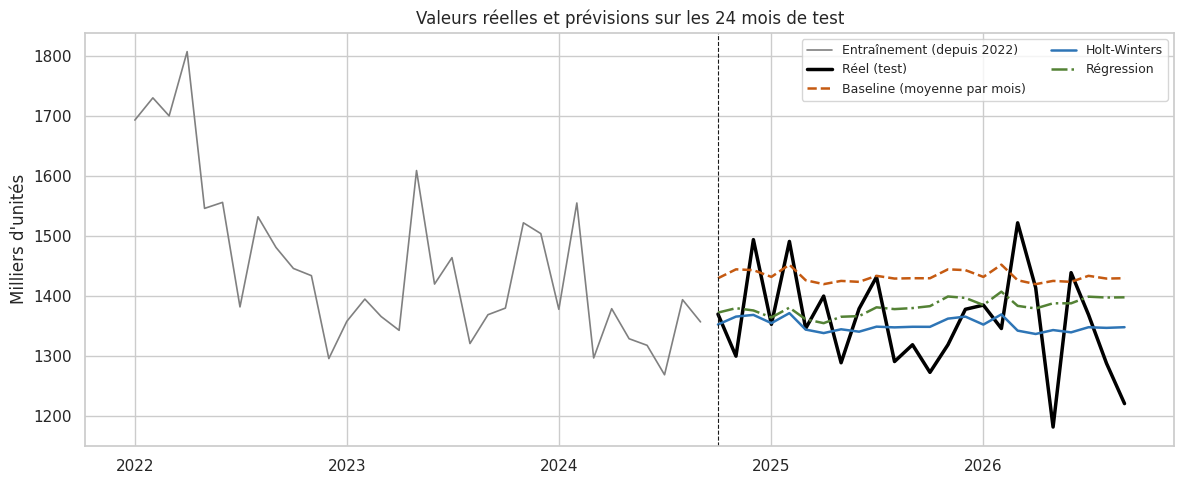

In [28]:
# Graphique : valeurs réelles et prévisions
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train["2022":].index, train["2022":].values, color="grey", lw=1.2, label="Entraînement (depuis 2022)")
ax.plot(test.index, test.values, color="black", lw=2.5, label="Réel (test)")
styles = {"Baseline (moyenne par mois)": ("#c55a11", "--"),
          "Holt-Winters": ("#2e75b6", "-"),
          "Régression": ("#548235", "-.")}
for nom, (c, ls) in styles.items():
    ax.plot(forecasts[nom].index, forecasts[nom].values, color=c, ls=ls, lw=1.8, label=nom)
ax.axvline(test.index[0], color="k", ls="--", lw=0.8)
ax.set_title("Valeurs réelles et prévisions sur les 24 mois de test"); ax.set_ylabel("Milliers d'unités")
ax.legend(ncol=2, fontsize=9)
plt.tight_layout(); plt.show()

,Baseline (moyenne par mois),Holt-Winters,Régression
mean,74.1,-7.0,23.6
std,82.4,82.5,86.9
min,-95.6,-179.5,-138.3
max,243.3,161.4,206.0


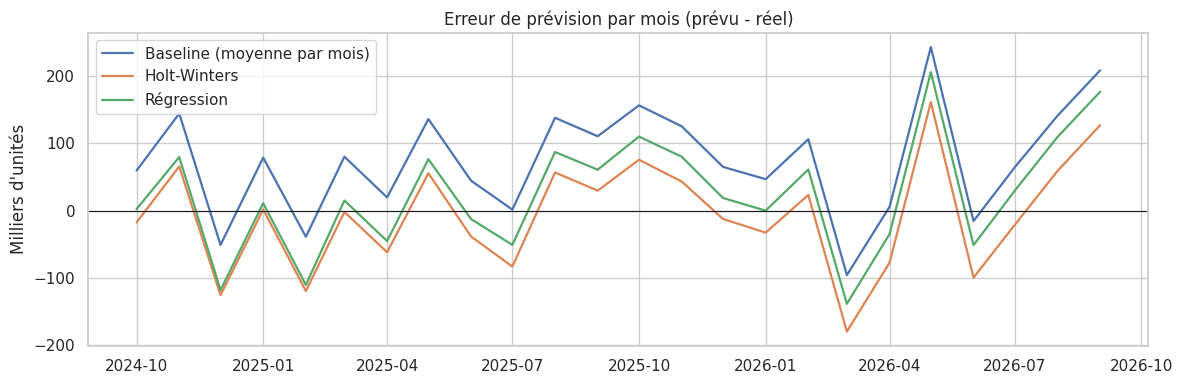

In [29]:
# Erreur de prévision = prévu - réel (positif = surestimation)
err = pd.DataFrame({nom: forecasts[nom] - test for nom in forecasts})
display(err.describe().loc[["mean", "std", "min", "max"]].round(1))

fig, ax = plt.subplots(figsize=(12, 4))
for nom in err.columns:
    ax.plot(err.index, err[nom], label=nom, lw=1.6)
ax.axhline(0, color="k", lw=0.8)
ax.set_title("Erreur de prévision par mois (prévu - réel)"); ax.set_ylabel("Milliers d'unités"); ax.legend()
plt.tight_layout(); plt.show()

### Résultats

| Modèle | RMSE | MAPE (%) |
|---|---|---|
| **Holt-Winters** | **81,03** | **4,81** |
| Régression (mois + lags) | 88,29 | 5,29 |
| Baseline (moyenne par mois) | 109,52 | 6,95 |

### Interprétation
- **Holt-Winters est le modèle le plus performant** (RMSE 81,0 ; MAPE 4,8 %), devant la régression (88,3 ; 5,3 %) et la baseline (109,5 ; 6,9 %).
- La baseline est la moins précise : elle prévoit un niveau presque constant (environ 1 430) alors que le niveau a changé. Son erreur moyenne est de **+74** (surestimation systématique), contre **−7** pour Holt-Winters et **+24** pour la régression.
- Sur le graphique, les trois prévisions sont presque plates, alors que les valeurs réelles oscillent fortement d'un mois à l'autre (d'environ 1 180 à 1 520). Les modèles ne reproduisent pas ces oscillations mensuelles : ils estiment surtout le bon niveau moyen, ce que Holt-Winters fait le mieux.
- L'erreur de Holt-Winters est d'environ 5 % en moyenne, ce qui est cohérent avec le bruit mensuel observé à l'étape 4 (écart-type de 8 % d'un mois à l'autre).

---
# Étape 10 — Interprétation et conclusion

### Réponse à la problématique
**Les mises en chantier de logements suivent-elles une saisonnalité prévisible ?** Sur la série `HOUST` fournie, **non** : aucun test ne détecte de saisonnalité mensuelle (ANOVA p = 0,751 ; Kruskal-Wallis p = 0,847), l'amplitude saisonnière de la décomposition (2,05 %) est trois fois inférieure au bruit résiduel (6,30 %), et les moyennes mensuelles d'entraînement sont presque identiques. Ce résultat s'explique par le fait que `HOUST` est une série déjà **corrigée des variations saisonnières**.

### Principaux résultats
- Série mensuelle complète de 813 observations, sans valeur manquante ni doublon, dominée par de grands cycles et de fortes variations de niveau.
- Sur les 24 derniers mois : Holt-Winters (RMSE 81,0 ; MAPE 4,8 %), régression (88,3 ; 5,3 %), baseline saisonnière (109,5 ; 6,9 %).

### Modèle le plus adapté
**Holt-Winters** : erreur la plus faible et absence de biais notable. Son paramètre saisonnier est nul et la régression s'appuie surtout sur les retards récents : la qualité de la prévision provient de l'adaptation du niveau aux données récentes et non de la saisonnalité.

### Limites
- La série est déjà corrigée des variations saisonnières : la saisonnalité réelle du secteur ne peut pas être mesurée avec ce fichier.
- Les mises en chantier sont révisées après publication : les valeurs récentes, utilisées pour le test, ne sont pas définitives.
- Le test ne comporte que 24 observations et un seul découpage est utilisé.
- Les ruptures structurelles (crise de 2008, Covid-19) rendent l'hypothèse de relations stables fragile.
- Aucune variable explicative externe n'est utilisée.

### Pistes d'amélioration
- Utiliser la série non corrigée `HOUSTNSA` pour étudier la saisonnalité réelle.
- Appliquer une validation glissante (*rolling origin*) pour évaluer les modèles sur plusieurs périodes.
- Ajouter des variables explicatives (taux hypothécaires, permis de construire).
- Tester d'autres modèles (SARIMA, gradient boosting avec retards) et produire des intervalles de prévision.